# GC Content and Melting Temperature

Compute GC/AT content, melting temperature (Wallace, GC and nearest-neighbor methods) and molecular weight of DNA sequences.

In [1]:
import numpy as np
from Bio.Seq import Seq

In [2]:
dna = Seq("CGATCGATCGAT")
print(dna)

CGATCGATCGAT


## GC content

GC content is the percentage of bases that are G or C. G-C pairs share three hydrogen bonds and A-T pairs only two, so GC-rich DNA is more stable. AT content is the remainder (100 - GC).

In [3]:
def GC_Counter(seq):
    gc =[]
    
    for x in seq:
        if x in "GC":
            gc.append(x)
    
    return len(gc) / len(seq) * 100

print(GC_Counter(dna))

50.0


In [4]:
gc = GC_Counter(dna)
at = 100 - gc
print(gc)
print(at)

50.0
50.0


In [5]:
from Bio.SeqUtils import gc_fraction
print(gc_fraction(dna) * 100)

50.0


In [6]:
import matplotlib.pyplot as plt

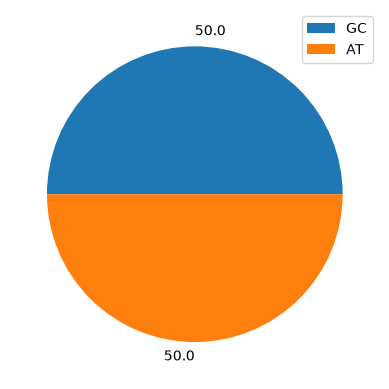

In [7]:
plt.pie(
    x = [gc, at],
    labels = [gc, at]
)
plt.legend(["GC", "AT"])
plt.show()

## Melting temperature

The melting temperature (Tm) is the temperature at which half of the DNA duplexes separate. Two rules of thumb: for short sequences (under 14 bases) use the Wallace rule, Tm = 2(A+T) + 4(G+C); for longer ones use Tm = 64.9 + 41 * (G+C - 16.4) / N. Biopython's `MeltingTemp` module also offers the more accurate nearest-neighbor method.

In [8]:
# Sequences shorter than 14 bases -> Wallace
# Sequences longer than 13 bases -> GC composition
# 2 * (A + T) + 4 * (G + C)
# 64.9 + 41 * (G + C - 16.4) / (A + T + G + C)

def MeltingTemperature(seq):
    g = seq.count("G")
    c = seq.count("C")
    a = seq.count("A")
    t = seq.count("T")

    wallace = 2 * (a + t) + 4 * (g + c)
    gc_composition = 64.9 + 41 * (g + c - 16.4) / (a + t + g + c)
    
    if len(seq) < 14:
        return wallace
    else:
        return gc_composition

In [9]:
print(MeltingTemperature(dna))

36


In [10]:
dna2 = Seq("CGATCGATCGATCGAT")
print(MeltingTemperature(dna2))

43.375000000000014


In [11]:
from Bio.SeqUtils import MeltingTemp as mt

In [12]:
print(mt.Tm_Wallace(dna))
print(mt.Tm_Wallace(dna2))

36.0
48.0


In [13]:
print(mt.Tm_GC(dna))
print(mt.Tm_GC(dna2))

30.40290207197791
42.902902071977906


In [14]:
print(mt.Tm_NN(dna))
print(mt.Tm_NN(dna2))

32.71608193055266
44.57810923234808


## Molecular weight

The molecular weight of a sequence is the sum of the masses of its nucleotides. Weighing the single-base strings below shows which base is heaviest.

In [15]:
from Bio.SeqUtils import molecular_weight as mw

In [16]:
print(mw(dna))
print(mw(dna2))

3725.3775
4961.1649


In [17]:
def split_nucleotide(seq, nucleotide):
    n = [x for x in seq if x in nucleotide]
    return "".join(n)

In [18]:
print(split_nucleotide(dna, "C"))
print(mw(split_nucleotide(dna, "C")))
print(mw(split_nucleotide(dna, "G")))
print(mw(split_nucleotide(dna, "A")))
print(mw(split_nucleotide(dna, "T")))

CCC
885.5606999999999
1005.633
957.6347999999998
930.5949
